# Extended Kalman Filter for the identification of uncertain parameters in MEMS

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

## Generates the same noisy measurements as in the MCMC example

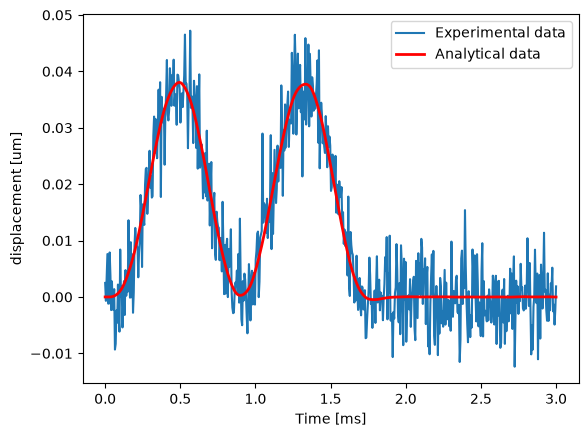

In [2]:
# parameters
M = 5.6e-09             # [kg]
Q = 0.7                 # Q factor
eps = 8.854e-12         # [F/m] vacuum permittivity
NA = 30e-6*200e-6 * 10  # [m^2] area of the electrode and 10 plates
g = 2e-6                # [m] gap of capacitor
tildef = 1200           # [Hz] forcing frequency

# time settings
dt = 5e-6                # time step [s]
t_0 = 0                 # initial time [s]
step = 600              # number of steps


def generate_KC(u): # u: double-sided overetch (um) 

    L = 200e-6              # [m] length of the beam
    E = 160e9               # [Pa] Young's Module of long beam
    b = (2.8 - u)*1e-6      # [m] width of the beam
    h = 30e-6               # [m] height of the beam
    I = h*b**3/12           # [m^4] second moment of area
    K = 2/6 * 12*E*I/L**3   # [N/m] stiffness of two springs
    eigen = np.sqrt(K/M)    # eigen frequency
    C = eigen/Q*M           # damping cufficient

    return K, C


def Analytical_Model(u):  # u: double-sided overetch (um) 

    # parameters
    K,C = generate_KC(u)    # stiffness [N/m] and C

    # Initial condition
    x0 = [0.0,              # initial displacement [m]
          0.0]              # initial velocity [m/s]

    # time setting
    dt = 5e-6               # time step [s]
    t_0 = 0                 # initial time [s]
    step = 600              # number of steps
    t_span = [t_0, step*dt] # time span [s]
    t_eval=np.arange(t_0, step*dt, dt)

    # RK45 solution
    def ode(t, state, *args):  
        x, dx = state
        K, M, C, eps, NA, g, tildef = args
        V = 1.2 * np.sin(tildef*np.pi*t) * (t<2/tildef)  # voltage [V]
        ddx = -K/M*x - C/M*dx + 1/2*eps*NA/M/(g-x)**2*V**2
        return [dx, ddx]

    sol = solve_ivp(ode, t_span, x0, args=(K, M, C, eps, NA, g, tildef), t_eval=t_eval)
    
    return sol.y[0]  # returns the displacement

u_true = np.array(0.45)      # real value of u
y_true = Analytical_Model(u_true)  # computes the time history of displacements for real value of u
nstep = len(y_true)

# corrupts data by adding Gaussian noise to the true data
sigma_noise = .5e-8 
np.random.seed(42)
y_observed = y_true + sigma_noise * np.random.randn(nstep)

# plot readout signal
t = np.linspace(0, 5e-6*nstep, nstep)
plt.figure()
plt.plot(t*1000, y_observed*1e6,label='Experimental data')
plt.plot(t*1000, y_true*1e6,label='Analytical data', color="red", linewidth="2")
plt.legend()
plt.xlabel('Time [ms]')
plt.ylabel('displacement [um]')
plt.show()
    
    

## Definition of the dynamic model

For parameter identification, the overetch is added to the state:
$$
\mathbf z =
\begin{bmatrix}
x\\ \dot x\\ u
\end{bmatrix},
\qquad
\dot u = 0.
$$
A small process noise will later be assigned to $u$ in the EKF, so that the parameter can adapt as measurements are assimilated.

In continuous time, the augmented deterministic dynamics are
$$
     \dot{\mathbf z} =
    \mathbf{g}(\mathbf{z},t)
    \quad \rightarrow \quad
    \frac{d}{dt}
    \begin{bmatrix}
        x\\[1mm]
        \dot{x}\\[1mm]
        u
    \end{bmatrix}
    =
    \begin{bmatrix}
        \dot{x}\\[2mm]
        -\dfrac{k(u)}{m}x
        -\dfrac{c(u)}{m}v
        +\dfrac{\varepsilon A}{2m(g-x)^2}V^2(t)\\[3mm]
        0
    \end{bmatrix}
%    \qquad v=\dot{x}.
$$


In [3]:
def Voltage(t):
    return 1.2 * np.sin(1200*np.pi*t) * (t < 2/1200)


def g_dyn(t, state):   
    """ defines array g(z,t) """
    
    x, dx, u = state

    K, C = generate_KC(u)
    eigen = np.sqrt(K/M)
    V = Voltage(t)

    ddx = (
        -K/M*x
        -C/M*dx
        + 0.5*eps*NA/M/(g-x)**2 * V**2
    )

    return np.array([dx, ddx, 0.0])


In the EKF we will need to propagate (integrate) numerically $\dot{\mathbf z} = \mathbf{g}(\mathbf{z},t)$ (actually the mean state) from $t_{k-1}$ to $t_k$. This will be done by means of RK45 in the function ``f``


In [4]:
def f(t0, state):      
    """Integrates dz/dt=g(z,t) from t0 to t0+dt."""

    sol = solve_ivp(
        g_dyn,
        (t0, t0+dt),
        state,
        t_eval=[t0+dt],
        rtol=1e-8,
        atol=1e-12
    )

    return sol.y[:, -1]


# Extended Kalman Filter

$$
    \mathbf{z}=
    \begin{bmatrix}
        x & \dot{x} & u
    \end{bmatrix}^{\top}.
$$

$$
\mathbf{z}_k = \mathbf{f}(\mathbf{z}_{k-1})+\mathbf{q}_k,
\qquad
\mathbf{q}_k =\begin{bmatrix} Q_x & Q_{\dot{x}} & Q_u]\end{bmatrix}^{\top}
$$
Only the displacement is observed, hence
$$
y_k = x_k+r_k =\mathbf H\mathbf z_k + r_k,
\qquad
\mathbf H = \begin{bmatrix}1&0&0\end{bmatrix},
\qquad
r_k\sim\mathcal N(0,R).
$$

All the initial covariance matrices need to be set

In [5]:
# Initial distribution: same mean and standard deviation used as prior in the MCMC example
prior_mean = 0.35       # [um]
prior_std = 0.07        # [um]

# Initial mean of the state
mu = np.array([
    0.0,                # displacement [m]
    0.0,                # velocity [m/s]
    prior_mean          # overetch [um]
])

# Initial covariance of the state
Sigma = np.diag([
    sigma_noise**2,     # initial displacement variance
    (1e-3)**2,          # initial velocity variance
    prior_std**2        # initial u variance
])

# Observation model
H = np.array([[1.0, 0.0, 0.0]])
R = sigma_noise**2

# Process-noise covariance
# The small nonzero u variance implements the random-walk parameter model.
Q_process = np.diag([1e-11**2, 1e-5**2, 1e-5**2])


## Discrete Transition Jacobian 

The discrete transition Jacobian of the linearized transition equation:
$$
\tilde{\mathbf{z}}_{k} \approx 
\underbrace{
\boldsymbol{\mu}_{k-1|k-1}+
\Delta t\,\mathbf{g}(\boldsymbol{\mu}_{k-1|k-1},t_{k-1})}_{\approx \, \mathbf{f}(\boldsymbol{\mu}_{k-1|k-1})}
+ \mathbf{F}_k\delta \mathbf{z}_{k-1}
$$
where:
$$    \mathbf{F}_k\simeq
    \mathbf{I}+\Delta t\,\mathbf{A}(\boldsymbol{\mu}_{k-1|k-1},t_{k-1})
    \qquad  \mathbf{A}(\mathbf{z},t)
    =\frac{\partial\mathbf{g}}{\partial\mathbf{z}}
$$
In our specific case, setting:
$$
    a(x,\dot{x},u,t)=
    -\frac{k(u)}{m}x
    -\frac{c(u)}{m}\dot{x}
    +\frac{N}{2m}\frac{\varepsilon A}{(g-x)^2}V^2(t).
$$
the continuous-time Jacobian of the augmented dynamics is
$$
    \mathbf{A}(\mathbf{z},t)
    =
    \begin{bmatrix}
        0 & 1 & 0\\[1mm]
        \dfrac{\partial a}{\partial x} &
        \dfrac{\partial a}{\partial \dot{x}} &
        \dfrac{\partial a}{\partial u}\\[2mm]
        0&0&0
    \end{bmatrix},
$$

$$
\begin{align}
    \frac{\partial a}{\partial x}
    &= -\frac{k(u)}{m}
    +\frac{N}{m}\frac{\varepsilon}{(g-x)^3}V^2(t),\\[1mm]
    \frac{\partial a}{\partial \dot{x}}
    &= -\frac{c(u)}{m},\\[1mm]
    \frac{\partial a}{\partial u}
    &= -\frac{k'(u)}{m}x
    -\frac{c'(u)}{m}\dot{x}.
\end{align}
$$


In [6]:
def dKC_du(u):
    """Derivative dK/du, with u measured in micrometres."""

    L = 200e-6
    E = 160e9
    h = 30e-6
    b = (2.8 - u)*1e-6
    db_du = -1e-6

    dI_du = h * 3*b**2 * db_du / 12
    dK_du = 2/6 * 12*E*dI_du/L**3

    K, C = generate_KC(u) 
    dC_du = 0.5 * C/K * dK_du

    return dK_du,dC_du


def A(t, state):
    """Jacobian A = dg/dz of the continuous augmented dynamics."""

    x, dx, u = state

    K , C  = generate_KC(u)
    dK_du, dC_du = dKC_du(u)

    V = Voltage(t)

    da_dx = -K/M + eps*NA/M * V**2/(g-x)**3
    da_ddx = -C/M
    da_du = -dK_du/M*x - dC_du/M*dx

    return np.array([
        [0.0,      1.0,       0.0],
        [da_dx, da_ddx, da_du],
        [0.0,      0.0,       0.0]
    ])


## EKF recursion

$$
\begin{align}
\text{Prediction of the state:}\qquad &
    \tilde{\mathbf{z}}_k\mid y_{1:k-1}
    \sim
    \mathcal{N}\!\left(
    \boldsymbol{\mu}_{k|k-1},
    \boldsymbol{\Sigma}_{k|k-1}
    \right),
    \\ & 
    \boldsymbol{\mu}_{k|k-1}
    = \mathbf{f}(\boldsymbol{\mu}_{k-1|k-1}),
    \\ &     \mathbf{F}_k=
    \mathbf{I}+\Delta t\,\mathbf{A}(\boldsymbol{\mu}_{k-1|k-1},t_{k-1}).
    \\ & 
    \boldsymbol{\Sigma}_{k|k-1}
    = \mathbf{F}_k\boldsymbol{\Sigma}_{k-1|k-1}\mathbf{F}_k^{\top}+\mathbf{Q},\\[1mm]
%
\text{Prediction of the measurement:}\qquad &
    \tilde{y}_k\mid y_{1:k-1}
    \sim
    \mathcal{N}\!\left(
    \mathbf{H}\boldsymbol{\mu}_{k|k-1},S_k
    \right),
\\ &
S_k = \mathbf{H}\boldsymbol{\Sigma}_{k|k-1}\mathbf{H}_k^{\top}+R,\\[1mm]
%
\text{Innovation, Kalman gain, update:}\qquad & 
\mathbf{z}_k \mid y_{1:k}
\sim
\mathcal{N}\left(
\mu_{k\mid k},
\boldsymbol{\Sigma}_{k\mid k}
\right)
\\ &
\nu_k
    = y_k-\mathbf{H}\boldsymbol{\mu}_{k|k-1},
    \\ & 
        \mathbf{K}_k
    = \boldsymbol{\Sigma}_{k|k-1}\mathbf{H}^{\top}S_k^{-1},
    \\ &
    \boldsymbol{\mu}_{k|k}
    = \boldsymbol{\mu}_{k|k-1}+\mathbf{K}_k\nu_k,
\\   
& \boldsymbol{\Sigma}_{k|k}
    = (\mathbf{I}-\mathbf{K}_k\mathbf{H}_k)\boldsymbol{\Sigma}_{k|k-1}.
\end{align}
$$

where $\mathbf{f}$ denotes numerical integration over one sampling interval and $\mathbf{Q}$ is the process-noise covariance. 
In the companion notebook, the Joseph form is used for numerical robustness,
$$
    \boldsymbol{\Sigma}_{k|k}
    =(\mathbf{I}-\mathbf{K}_k\mathbf{H})
    \boldsymbol{\Sigma}_{k|k-1}
    (\mathbf{I}-\mathbf{K}_k\mathbf{H})^{\top}
    +\mathbf{K}_k R\mathbf{K}_k^{\top}.
$$
The equivalence of the Joseph form can be shown with lengthy calculations, here skipped.


In [7]:
mu_history = np.zeros((nstep, 3))
Sigma_history = np.zeros((nstep, 3, 3))
innovation_history = np.full(nstep, np.nan)

time = np.arange(nstep) * dt
I3 = np.eye(3)

# Initial estimate at k = 0
mu_history[0] = mu
Sigma_history[0] = Sigma

for k in range(1, nstep):

    t=time[k-1] 
    
    # prediction 
    mu = f(t, mu)
    F = I3 + dt * A(t, mu)
    Sigma = F @ Sigma @ F.T + Q_process
    S = (H @ Sigma @ H.T)[0, 0] + R

    # update
    innovation = y_observed[k] - (H @ mu)[0]
    K_gain = (Sigma @ H.T)[:, 0] / S
    mu += K_gain * innovation
    # Joseph covariance update
    KH = np.outer(K_gain, H[0])
    Sigma = ((I3 - KH) @ Sigma @ (I3 - KH).T+ np.outer(K_gain, K_gain) * R)

    mu_history[k] = mu
    Sigma_history[k] = Sigma
    innovation_history[k] = innovation


print(f'True overetch:       {u_true:.4f} um')
print(f'Initial estimate:    {prior_mean:.4f} um')
print(f'Final EKF estimate:  {mu_history[-1,2]:.4f} um')
print(f'Final EKF std:       {np.sqrt(Sigma_history[-1,2,2]):.4f} um')

True overetch:       0.4500 um
Initial estimate:    0.3500 um
Final EKF estimate:  0.4480 um
Final EKF std:       0.0119 um


**Comments**

`H @ Sigma @ H.T` has shape (1, 1) because there is one measurement. `[0, 0]` extracts its single entry, so S is a scalar.
`Sigma @ H.T` has shape (3, 1) because the state has three components. `[:, 0]` extracts its only column, so ``K_gain`` has shape (3,).

## Evolution of the estimated overetch

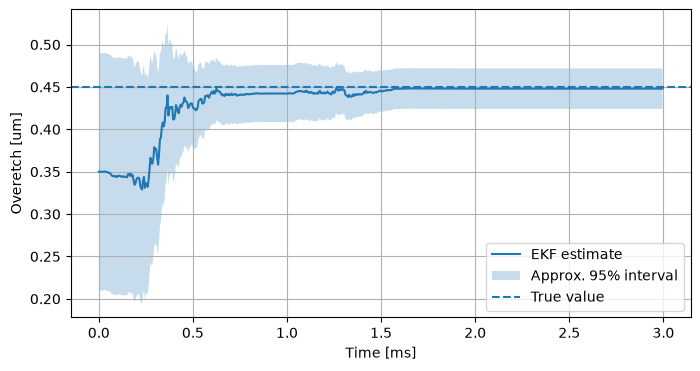

In [8]:
u_est = mu_history[:, 2]
u_std = np.sqrt(Sigma_history[:, 2, 2])

plt.figure(figsize=(8, 4))
plt.plot(time*1000, u_est, label='EKF estimate')
plt.fill_between(
    time*1000,
    u_est - 2*u_std,
    u_est + 2*u_std,
    alpha=0.25,
    label='Approx. 95% interval'
)
plt.axhline(u_true, linestyle='--', label='True value')
plt.xlabel('Time [ms]')
plt.ylabel('Overetch [um]')
plt.legend()
plt.grid()
plt.show()

## Estimated displacement

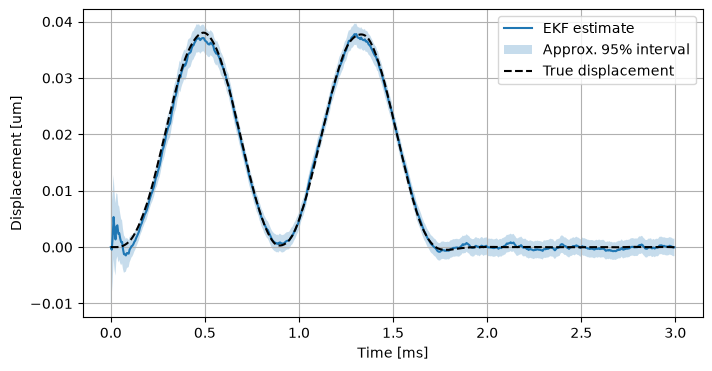

In [9]:
x_est = mu_history[:, 0] * 1e6  # displacement estimate [um]
x_std = np.sqrt(Sigma_history[:, 0, 0]) * 1e6  # displacement std [um]
x_true = y_true * 1e6  # true displacement [um]

plt.figure(figsize=(8, 4))
plt.plot(time*1000, x_est, label='EKF estimate')
plt.fill_between(
    time*1000,
    x_est - 2*x_std,
    x_est + 2*x_std,
    alpha=0.25,
    label='Approx. 95% interval'
)
plt.plot(time*1000, x_true, linestyle='--', color='black', label='True displacement')
plt.xlabel('Time [ms]')
plt.ylabel('Displacement [um]')
plt.legend()
plt.grid()
plt.show()

## Comment

The EKF uses the measurements sequentially. At the beginning, the overetch estimate is close to its prior mean. As the transient develops, the displacement becomes informative about the suspension stiffness and therefore about the overetch. The uncertainty on $u$ progressively decreases.

Unlike MCMC, the EKF dus not reconstruct an arbitrary posterior density. It approximates the current posterior by a Gaussian distribution characterized by the estimated mean and covariance. This makes the method very inexpensive and suitable for online identification, at the price of the local linearization introduced by the EKF.